### Goal

1. Load the five selected 48D datasets and best hyperparameters from the tuning summaries.
2. Train the five tuned classifiers on all 960 training recordings.
3. Evaluate training accuracy, training Macro-F1, validation accuracy and validation Macro-F1 on the same 240 validation recordings.
4. Load the previously saved default results and display a comparison table, plus one simple default-versus-tuned validation Macro-F1 chart.

In [ ]:
# Imports and project paths

from pathlib import Path
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score

from xgboost import XGBClassifier

In [5]:
# Locate project root automatically
current_dir = Path.cwd().resolve()

PROJECT_ROOT = None

for directory in [current_dir, *current_dir.parents]:

    if (
        (directory / "outputs/features/experimental_v2/combined").exists()
        and
        (directory / "outputs/metrics/experimental_v2/tuning").exists()
    ):
        PROJECT_ROOT = directory
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Project root not found from {current_dir}. "
        "Check the notebook working directory."
    )

FEATURE_DIR = (
    PROJECT_ROOT / "outputs/features/experimental_v2/combined"
)

METRICS_DIR = (
    PROJECT_ROOT / "outputs/metrics/experimental_v2"
)

TUNING_DIR = METRICS_DIR / "tuning"

print("Current directory:", current_dir)
print("Project root:", PROJECT_ROOT)
print("Feature directory exists:", FEATURE_DIR.exists())
print("Tuning directory exists:", TUNING_DIR.exists())

Current directory: D:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted\notebooks\experimental_v2
Project root: D:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted
Feature directory exists: True
Tuning directory exists: True


In [ ]:
# Define the five classifiers and their datasets

MODEL_CONFIGS = {
    "Logistic Regression": {
        "key": "logistic_regression",
        "wavelet": "db2",
        "normalization": "norm",
        "frame_ms": 20,
    },

    "MLP": {
        "key": "mlp_round2",
        "wavelet": "sym4",
        "normalization": "raw",
        "frame_ms": 20,
    },

    "SVC": {
        "key": "svc",
        "wavelet": "sym4",
        "normalization": "norm",
        "frame_ms": 25,
    },

    "XGBoost": {
        "key": "xgboost",
        "wavelet": "db8",
        "normalization": "raw",
        "frame_ms": 30,
    },

    "Random Forest": {
        "key": "random_forest",
        "wavelet": "db8",
        "normalization": "raw",
        "frame_ms": 30,
    },
}

EMOTIONS = [
    "neutral", "calm", "happy", "sad",
    "angry", "fearful", "disgust", "surprised"
]

LABEL_MAP = {
    emotion: index
    for index, emotion in enumerate(EMOTIONS)
}

METADATA_COLUMNS = [
    "sample_id",
    "actor_id",
    "emotion_label",
    "split",
]

print("Models configured:", len(MODEL_CONFIGS))

Models configured: 5


In [7]:
# Load datasets and construct classifiers

def load_dataset(config):

    file_path = (
        FEATURE_DIR
        / config["wavelet"]
        / (
            f"combined_{config['normalization']}_"
            f"{config['frame_ms']}ms.csv"
        )
    )

    df = pd.read_csv(file_path)

    feature_columns = [
        col for col in df.columns
        if col not in METADATA_COLUMNS
    ]

    train_df = df[df["split"] == "train"]
    val_df = df[df["split"] == "val"]

    X_train = train_df[feature_columns]
    X_val = val_df[feature_columns]

    y_train = train_df["emotion_label"].map(LABEL_MAP)
    y_val = val_df["emotion_label"].map(LABEL_MAP)

    assert len(feature_columns) == 48
    assert len(train_df) == 960
    assert len(val_df) == 240
    assert y_train.notna().all()
    assert y_val.notna().all()

    assert set(train_df["actor_id"]).isdisjoint(
        set(val_df["actor_id"])
    )

    assert np.isfinite(X_train.to_numpy()).all()
    assert np.isfinite(X_val.to_numpy()).all()

    return (
        X_train,
        y_train.astype(int),
        X_val,
        y_val.astype(int),
    )


def create_model(model_name, params):

    if model_name == "Logistic Regression":
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=3000,
                random_state=42,
            ),
        )

    elif model_name == "MLP":
        model = make_pipeline(
            StandardScaler(),
            MLPClassifier(
                solver="adam",
                max_iter=1000,
                tol=1e-4,
                n_iter_no_change=30,
                early_stopping=False,
                random_state=42,
            ),
        )

    elif model_name == "SVC":
        model = make_pipeline(
            StandardScaler(),
            SVC(),
        )

    elif model_name == "XGBoost":
        model = XGBClassifier(
            objective="multi:softprob",
            num_class=8,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=42,
            n_jobs=1,
        )

    elif model_name == "Random Forest":
        model = RandomForestClassifier(
            bootstrap=True,
            random_state=42,
            n_jobs=1,
        )

    else:
        raise ValueError(f"Unknown classifier: {model_name}")

    model.set_params(**params)

    return model

In [8]:
# Train and evaluate all five tuned classifiers

results = []

for model_name, config in MODEL_CONFIGS.items():

    print(f"\nTraining: {model_name}")

    # Load best CV-selected hyperparameters
    summary_path = (
        TUNING_DIR / f"{config['key']}_summary.csv"
    )

    summary = pd.read_csv(summary_path)

    best_params = ast.literal_eval(
        summary.iloc[0]["best_params"]
    )

    # Load selected dataset
    X_train, y_train, X_val, y_val = load_dataset(config)

    # Create and train classifier
    model = create_model(model_name, best_params)

    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Evaluation
    train_accuracy = accuracy_score(y_train, train_pred)
    train_macro_f1 = f1_score(
        y_train, train_pred,
        average="macro",
        zero_division=0,
    )

    val_accuracy = accuracy_score(y_val, val_pred)
    val_macro_f1 = f1_score(
        y_val, val_pred,
        average="macro",
        zero_division=0,
    )

    results.append({
        "classifier": model_name,
        "wavelet": config["wavelet"],
        "normalization": config["normalization"],
        "frame_ms": config["frame_ms"],
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "f1_gap": train_macro_f1 - val_macro_f1,
    })

    print(f"Train Macro-F1: {train_macro_f1:.4f}")
    print(f"Val Macro-F1:   {val_macro_f1:.4f}")
    print(f"Val Accuracy:   {val_accuracy:.4f}")

tuned_df = pd.DataFrame(results)

display(
    tuned_df.sort_values(
        "val_macro_f1",
        ascending=False,
    ).round(4)
)


Training: Logistic Regression
Train Macro-F1: 0.4705
Val Macro-F1:   0.3745
Val Accuracy:   0.3958

Training: MLP
Train Macro-F1: 0.6622
Val Macro-F1:   0.3331
Val Accuracy:   0.3708

Training: SVC
Train Macro-F1: 0.4784
Val Macro-F1:   0.3535
Val Accuracy:   0.3667

Training: XGBoost
Train Macro-F1: 0.8074
Val Macro-F1:   0.3627
Val Accuracy:   0.3917

Training: Random Forest
Train Macro-F1: 0.9781
Val Macro-F1:   0.3315
Val Accuracy:   0.3583


,classifier,wavelet,normalization,frame_ms,train_accuracy,train_macro_f1,val_accuracy,val_macro_f1,f1_gap
0,Logistic Regression,db2,norm,20,0.4896,0.4705,0.3958,0.3745,0.0960
3,XGBoost,db8,raw,30,0.8094,0.8074,0.3917,0.3627,0.4446
2,SVC,sym4,norm,25,0.4906,0.4784,0.3667,0.3535,0.1248
1,MLP,sym4,raw,20,0.6781,0.6622,0.3708,0.3331,0.3291
4,Random Forest,db8,raw,30,0.9781,0.9781,0.3583,0.3315,0.6466


In [9]:
# Compare against the default classifiers

default_df = pd.read_csv(
    METRICS_DIR / "best_preprocessing_per_classifier.csv"
)

default_df = default_df[
    default_df["classifier"].isin(MODEL_CONFIGS)
].copy()

comparison_df = default_df.merge(
    tuned_df,
    on="classifier",
    suffixes=("_default", "_tuned"),
    validate="one_to_one",
)

# Confirm same preprocessing configuration
for col in ["wavelet", "normalization", "frame_ms"]:
    assert (
        comparison_df[f"{col}_default"]
        == comparison_df[f"{col}_tuned"]
    ).all()

comparison_df["f1_change"] = (
    comparison_df["val_macro_f1_tuned"]
    - comparison_df["val_macro_f1_default"]
)

comparison_df["accuracy_change"] = (
    comparison_df["val_accuracy_tuned"]
    - comparison_df["val_accuracy_default"]
)

display(
    comparison_df[
        [
            "classifier",
            "train_macro_f1_default",
            "train_macro_f1_tuned",
            "val_macro_f1_default",
            "val_macro_f1_tuned",
            "f1_change",
            "val_accuracy_default",
            "val_accuracy_tuned",
            "accuracy_change",
        ]
    ].sort_values(
        "val_macro_f1_tuned",
        ascending=False,
    ).round(4)
)

,classifier,train_macro_f1_default,train_macro_f1_tuned,val_macro_f1_default,val_macro_f1_tuned,f1_change,val_accuracy_default,val_accuracy_tuned,accuracy_change
0,Logistic Regression,0.5084,0.4705,0.3885,0.3745,-0.0140,0.4000,0.3958,-0.0042
2,XGBoost,1.0000,0.8074,0.3687,0.3627,-0.0059,0.3958,0.3917,-0.0042
3,SVC,0.6840,0.4784,0.3413,0.3535,0.0122,0.3625,0.3667,0.0042
1,MLP,0.9219,0.6622,0.3692,0.3331,-0.0361,0.3833,0.3708,-0.0125
4,Random Forest,1.0000,0.9781,0.3259,0.3315,0.0056,0.3542,0.3583,0.0042


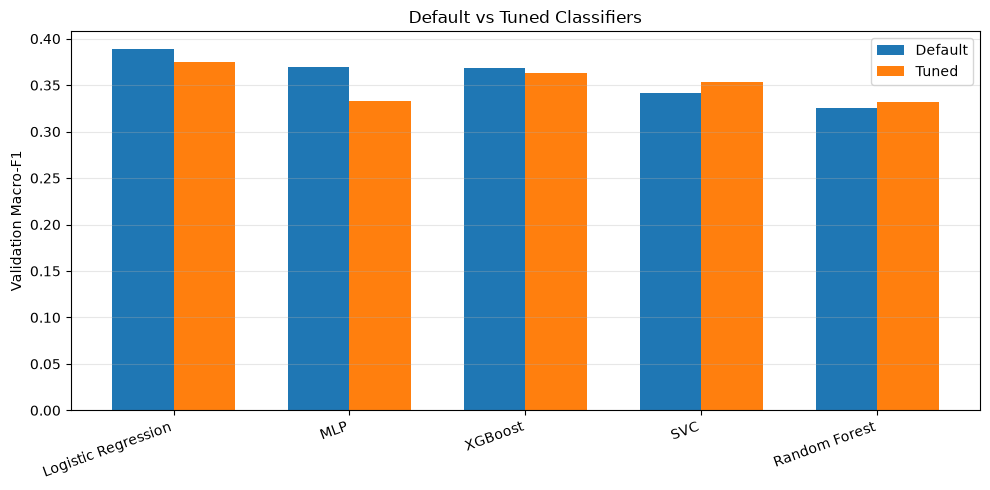

In [10]:
# Plot default vs tuned validation Macro-F1

plot_df = comparison_df.sort_values(
    "val_macro_f1_default",
    ascending=False,
)

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    plot_df["val_macro_f1_default"],
    width,
    label="Default",
)

ax.bar(
    x + width / 2,
    plot_df["val_macro_f1_tuned"],
    width,
    label="Tuned",
)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["classifier"],
    rotation=20,
    ha="right",
)

ax.set_ylabel("Validation Macro-F1")
ax.set_title("Default vs Tuned Classifiers")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Save the final comparison

output_path = (
    METRICS_DIR / "default_vs_tuned_comparison.csv"
)

comparison_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: D:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted\outputs\metrics\experimental_v2\default_vs_tuned_comparison.csv


In [12]:
best_versions = comparison_df.copy()

best_versions["best_version"] = np.where(
    best_versions["val_macro_f1_tuned"]
    > best_versions["val_macro_f1_default"],
    "Tuned",
    "Default",
)

best_versions["best_val_macro_f1"] = best_versions[
    ["val_macro_f1_default", "val_macro_f1_tuned"]
].max(axis=1)

best_versions["best_val_accuracy"] = np.where(
    best_versions["best_version"] == "Tuned",
    best_versions["val_accuracy_tuned"],
    best_versions["val_accuracy_default"],
)

best_versions = best_versions.sort_values(
    "best_val_macro_f1",
    ascending=False,
)

display(
    best_versions[
        [
            "classifier",
            "best_version",
            "best_val_macro_f1",
            "best_val_accuracy",
        ]
    ].round(4)
)

,classifier,best_version,best_val_macro_f1,best_val_accuracy
0,Logistic Regression,Default,0.3885,0.4000
1,MLP,Default,0.3692,0.3833
2,XGBoost,Default,0.3687,0.3958
3,SVC,Tuned,0.3535,0.3667
4,Random Forest,Tuned,0.3315,0.3583
